In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.listdir("results")

['stoch_100_0cells_h32_k3_complexity.csv',
 'stoch_gene_wise_100_0cells_h32_k3_complexity.csv',
 'stoch_gene_wise_h32_k3_complexity.csv',
 'negotiate_1000_3cells_h32_k3_complexity.csv',
 'negotiate_100_3cells_h32_k3_complexity.csv',
 'negotiate_100_0cells_h32_k3_complexity.csv',
 'new_negotiate_100_0cells_h32_k3_complexity.csv',
 'negotiate_1000_0cells_h32_k3_complexity.csv',
 'new_negotiate_100_3cells_h32_k3_complexity.csv']

In [2]:
data = pd.DataFrame(columns=["name", "seed", "t", "Loss"])
for file in os.listdir("results"):
    name= file.split(".")[0]
    tmp = pd.read_csv("results/"+file)
    tmp["name"] = name
    data = pd.concat([data, tmp])

data["t"] = (data["t"]*250).astype(int)
data["Loss"] = data["Loss"].astype(float)
data["seed"] = data["seed"].astype(int)
data["name"] = data["name"].astype(str)
data = data.rename(columns={"t": "Time", "Loss": "Loss", "seed": "Seed", "name": "Name"})
data = data.drop(columns=["Unnamed: 0"])
data = data.reset_index()
data.head(10)

/tmp/ipykernel_32665/1929668761.py:6: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data, tmp])


,index,Name,Seed,Time,Loss
0,0,stoch_100_0cells_h32_k3_complexity,0,0,NaN
1,1,stoch_100_0cells_h32_k3_complexity,0,250,NaN
2,2,stoch_100_0cells_h32_k3_complexity,0,500,NaN
3,3,stoch_100_0cells_h32_k3_complexity,0,750,NaN
4,4,stoch_100_0cells_h32_k3_complexity,0,1000,NaN
5,5,stoch_100_0cells_h32_k3_complexity,0,1250,NaN
6,6,stoch_100_0cells_h32_k3_complexity,0,1500,NaN
7,7,stoch_100_0cells_h32_k3_complexity,0,1750,0.037531
8,8,stoch_100_0cells_h32_k3_complexity,0,2000,0.035922
9,9,stoch_100_0cells_h32_k3_complexity,0,2250,0.033237


Text(0.5, 0, 'Time (Iterations)')

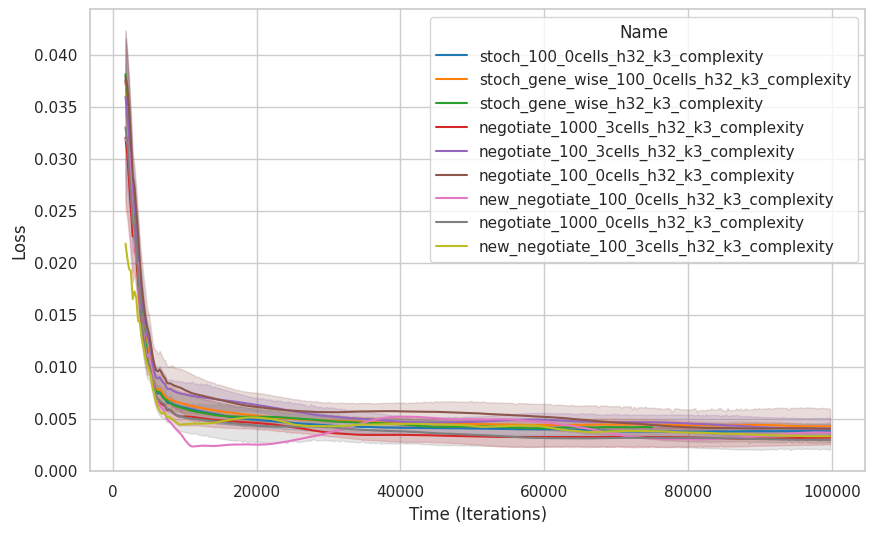

In [3]:
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.lineplot(data=data, x="Time", y="Loss", hue="Name", palette="tab10")
plt.xlabel("Time (Iterations)")

Text(0.5, 0, 'Time (Iterations)')

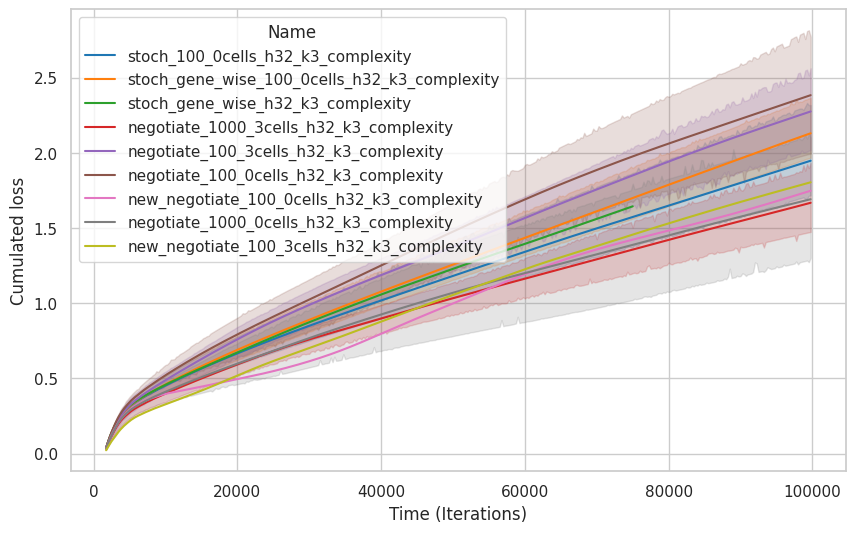

In [4]:
# compute cumulated loss over t
data["Cumulated loss"] = data.groupby(["Name", "Seed"])["Loss"].cumsum()
plt.figure(figsize=(10, 6))
sns.lineplot(data=data, x="Time", y="Cumulated loss", hue="Name", palette="tab10")
plt.xlabel("Time (Iterations)")


Text(0.5, 1.0, 'negotiate_100_3cells_h32_k3_complexity')

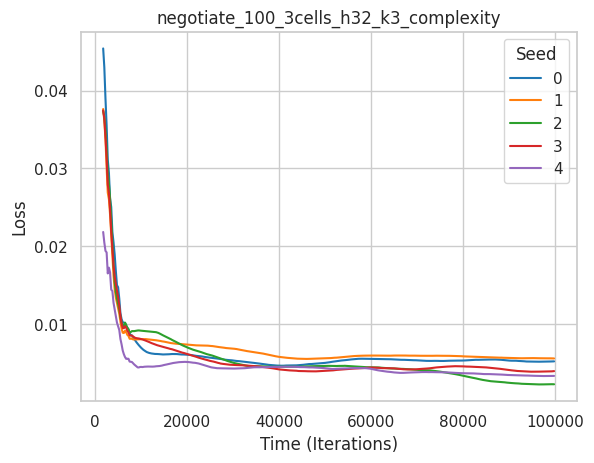

In [5]:
sns.lineplot(data=data[data["Name"]=="negotiate_100_3cells_h32_k3_complexity"], x="Time", y="Loss", hue="Seed", palette="tab10")
plt.xlabel("Time (Iterations)")
plt.title("negotiate_100_3cells_h32_k3_complexity")

# Video

In [33]:
vid_data = pd.DataFrame(columns=["name", "seed", "time", "size"])

for folder in os.listdir("vid_results"):
    for file in os.listdir("vid_results/"+folder):
        name = folder
        seed = int(file.split("_")[1])
        d = pd.read_csv("vid_results/"+folder+"/"+file)
        d["name"] = name
        d["seed"] = seed
        vid_data = pd.concat([vid_data, d])

vid_data["time"] = vid_data["time"].astype(float)
vid_data["size"] = vid_data["size"].astype(int)
vid_data["seed"] = vid_data["seed"].astype(int)
vid_data["name"] = vid_data["name"].astype(str)
vid_data = vid_data.rename(columns={"time": "Time", "size": "Compressed size", "seed": "Seed", "name": "Name"})
vid_data = vid_data.drop(columns=["Unnamed: 0"])
vid_data = vid_data.reset_index()
vid_data = vid_data.drop(index=vid_data[vid_data["Name"] == "neglarge"].index)


vid_data.head(10)
    

,index,Name,Seed,Time,Compressed size
1660,0,nego_beta100,0,0.0,204291
1661,1,nego_beta100,0,1.0,177692
1662,2,nego_beta100,0,2.0,224155
1663,3,nego_beta100,0,3.0,213909
1664,4,nego_beta100,0,4.0,196487
1665,5,nego_beta100,0,5.0,192071
1666,6,nego_beta100,0,6.0,198409
1667,7,nego_beta100,0,7.0,210563
1668,8,nego_beta100,0,8.0,215058
1669,9,nego_beta100,0,9.0,201281


Text(0.5, 1.0, 'Compressed size over time (1s window)')

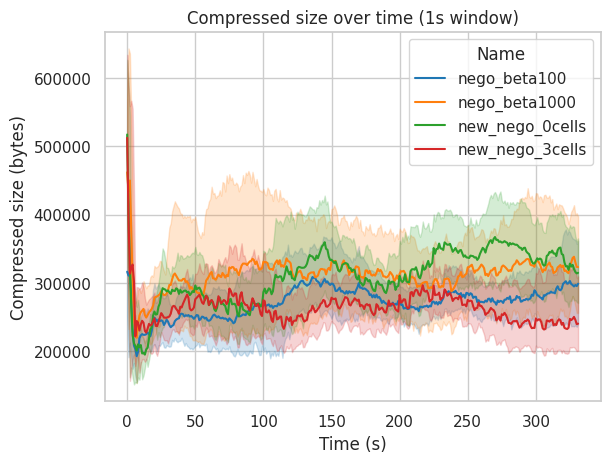

In [36]:
sns.lineplot(data=vid_data, x="Time", y="Compressed size", hue="Name", palette="tab10")
plt.xlabel("Time (s)")
plt.ylabel("Compressed size (bytes)")
plt.title("Compressed size over time (1s window)")

Text(0.5, 1.0, 'Cumulated compressed size over time (1s window)')

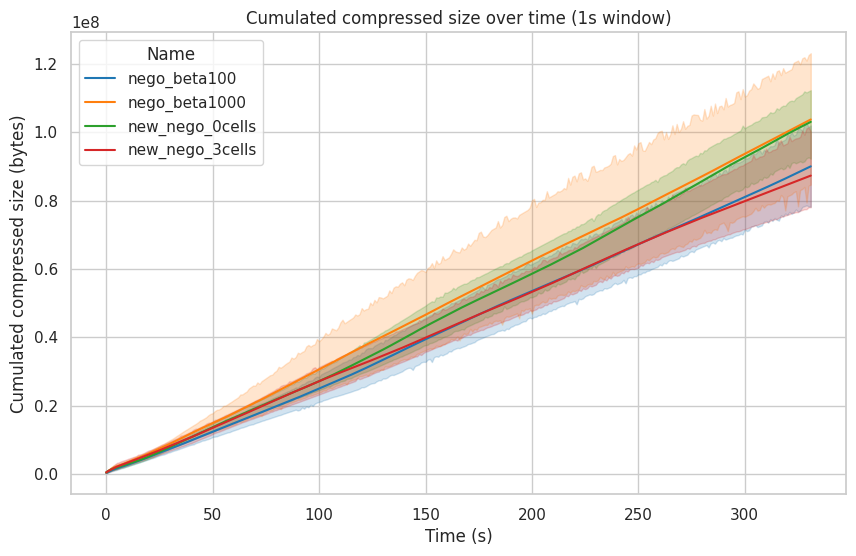

In [38]:
vid_data["Cumulated compressed size"] = vid_data.groupby(["Name", "Seed"])["Compressed size"].cumsum()
plt.figure(figsize=(10, 6))
sns.lineplot(data=vid_data, x="Time", y="Cumulated compressed size", hue="Name", palette="tab10")
plt.xlabel("Time (s)")
plt.ylabel("Cumulated compressed size (bytes)")
plt.title("Cumulated compressed size over time (1s window)")

Text(0.5, 1.0, 'nego_beta100')

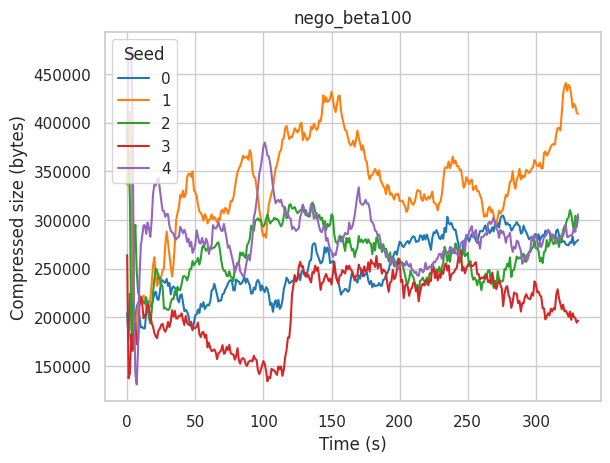

In [41]:
sns.lineplot(data=vid_data[vid_data["Name"]=="nego_beta100"], x="Time", y="Compressed size", hue="Seed", palette="tab10")
plt.xlabel("Time (s)")
plt.ylabel("Compressed size (bytes)")
plt.title("nego_beta100")